In [9]:
# Part 1: Import Required Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

sns.set_style('whitegrid')
tf.keras.utils.set_random_seed(42)

In [10]:
# Part 2: Define Dataset Paths
# Kaggle's standard path is preferred. Otherwise, search /kaggle/input for the three split folders.
BASE_DIR = '/kaggle/input/vegetable-image-dataset/Vegetable Images'

if not all(os.path.isdir(os.path.join(BASE_DIR, split)) for split in ('train', 'test', 'validation')):
    BASE_DIR = None
    for root, dirs, _ in os.walk('/kaggle/input'):
        if {'train', 'test', 'validation'}.issubset(set(dirs)):
            BASE_DIR = root
            break

# For local/Colab use, replace the value below with your extracted dataset folder if needed.
# Example: BASE_DIR = '/content/Vegetable Images'
if BASE_DIR is None:
    raise FileNotFoundError(
        "Vegetable dataset not found. In Kaggle, click 'Add Input' and attach "
        "'Vegetable Image Dataset'. For local/Colab, set BASE_DIR to the folder "
        "that contains train, test, and validation."
    )

train_dir = os.path.join(BASE_DIR, 'train')
test_dir = os.path.join(BASE_DIR, 'test')
validation_dir = os.path.join(BASE_DIR, 'validation')
print('Dataset path:', BASE_DIR)
print('Train / Test / Validation folders found:', all(os.path.isdir(p) for p in [train_dir, test_dir, validation_dir]))

Dataset path: /kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images
Train / Test / Validation folders found: True


In [11]:
# Part 3: Count Images in Each Class
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png')

def count_images(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([f for f in os.listdir(class_path) if f.lower().endswith(IMAGE_EXTENSIONS)])
    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
validation_counts = count_images(validation_dir)

print("Train:", train_counts)
print("Test:", test_counts)
print("Validation:", validation_counts)

Train: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
Test: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}
Validation: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [12]:
# Part 4: Create a Summary DataFrame
train_df = pd.DataFrame(list(train_counts.items()), columns=['Vegetable', 'Train Count'])
test_df = pd.DataFrame(list(test_counts.items()), columns=['Vegetable', 'Test Count'])
validation_df = pd.DataFrame(list(validation_counts.items()), columns=['Vegetable', 'Validation Count'])

final_df = train_df.merge(test_df, on='Vegetable').merge(validation_df, on='Vegetable')
final_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


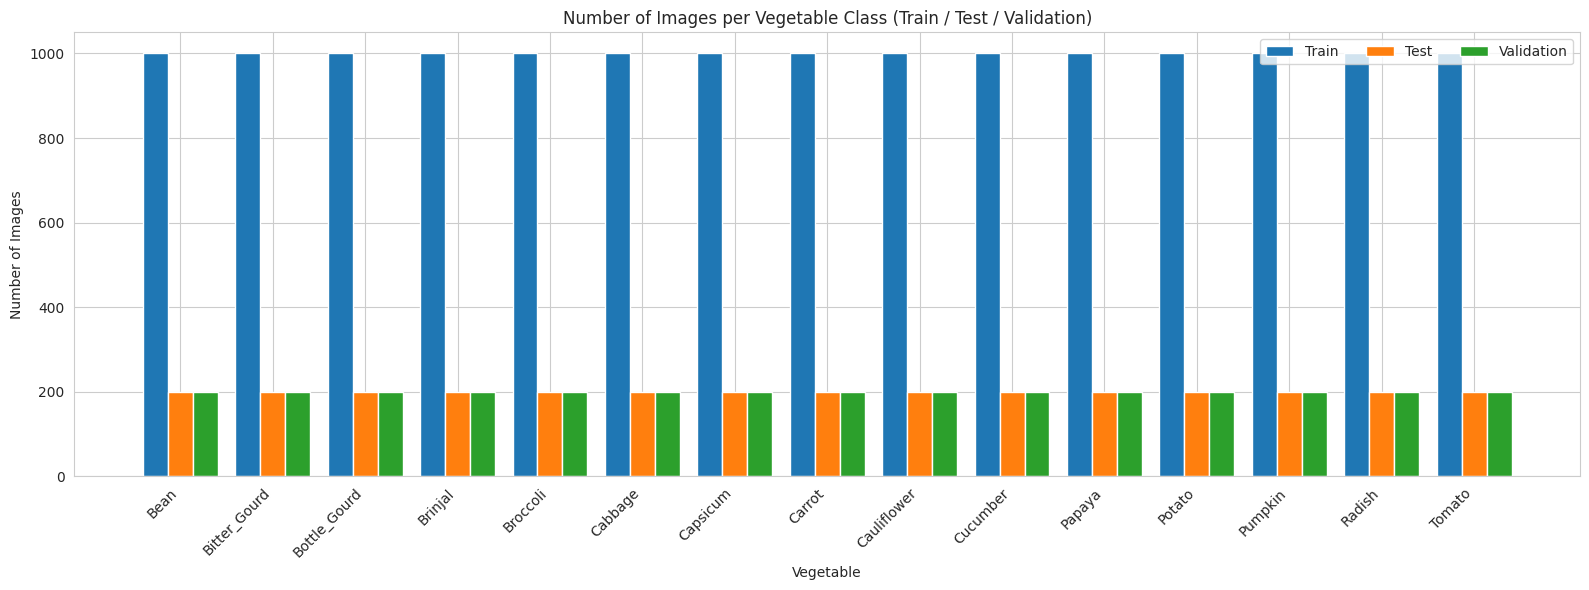

Train Count: min=1000, max=1000, max/min ratio=1.00
Test Count: min=200, max=200, max/min ratio=1.00
Validation Count: min=200, max=200, max/min ratio=1.00
Is the dataset balanced? Yes - every class has almost the same number of images in each split.


In [13]:
# Part 5: Visualize Class Distribution
x = np.arange(len(final_df))
width = 0.27

plt.figure(figsize=(16, 6))
plt.bar(x - width, final_df['Train Count'], width, label='Train')
plt.bar(x, final_df['Test Count'], width, label='Test')
plt.bar(x + width, final_df['Validation Count'], width, label='Validation')
plt.xticks(x, final_df['Vegetable'], rotation=45, ha='right')
plt.xlabel('Vegetable')
plt.ylabel('Number of Images')
plt.title('Number of Images per Vegetable Class (Train / Test / Validation)')
plt.legend(loc='upper right', ncol=3)
plt.tight_layout()
plt.show()

for split in ['Train Count', 'Test Count', 'Validation Count']:
    lo, hi = final_df[split].min(), final_df[split].max()
    ratio = hi / lo if lo else float('inf')
    print(f'{split}: min={lo}, max={hi}, max/min ratio={ratio:.2f}')

balanced = all(
    final_df[s].min() > 0 and final_df[s].max() / final_df[s].min() <= 1.1
    for s in ['Train Count', 'Test Count', 'Validation Count']
)
if balanced:
    print('Is the dataset balanced? Yes - every class has almost the same number of images in each split.')
else:
    print('Is the dataset balanced? No - image counts differ across classes. Consider this when interpreting model performance.')

In [14]:
# Part 6: Image Preprocessing and Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [15]:
# Part 7: Load Images Using flow_from_directory
# Augmented generator is used only for model training.
train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    seed=42,
    shuffle=True
)

# Non-augmented generators are used for fair evaluation.
eval_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)
train_eval_ds = eval_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    seed=42,
    shuffle=False
)
val_ds = eval_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    seed=42,
    shuffle=False
)

# The held-out test split is not used during training or model selection.
test_datagen = ImageDataGenerator(rescale=1./255)
test_ds = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

print('Class indices:', train_ds.class_indices)
assert train_ds.class_indices == val_ds.class_indices == test_ds.class_indices, \
    'Class folders/order differ between train, validation, and test splits.'

Found 12000 images belonging to 15 classes.
Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Class indices: {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


In [16]:
# Part 8: Build the CNN Model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(15, activation='softmax')
])

In [17]:
# Part 9: Compile the Model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

n_conv = sum(isinstance(l, layers.Conv2D) for l in model.layers)
print("Number of convolutional layers:", n_conv)
print("Pooling layers: reduce the spatial size of the feature maps, which cuts computation and parameters and makes the model less sensitive to small shifts of objects.")
print("Dropout: randomly turns off 50% of the neurons during training so the network cannot depend on specific neurons, which reduces overfitting.")
print("Softmax: turns the 15 output scores into probabilities that sum to 1, so the class with the highest probability is the prediction (multi-class classification).")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

Number of convolutional layers: 3
Pooling layers: reduce the spatial size of the feature maps, which cuts computation and parameters and makes the model less sensitive to small shifts of objects.
Dropout: randomly turns off 50% of the neurons during training so the network cannot depend on specific neurons, which reduces overfitting.
Softmax: turns the 15 output scores into probabilities that sum to 1, so the class with the highest probability is the prediction (multi-class classification).


In [18]:
# Part 10: Train the Model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

print("EarlyStopping is useful because it stops training when the validation loss stops improving, which saves time, prevents overfitting, and restores the best weights.")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1296s 3s/step - accuracy: 0.5067 - loss: 1.4458 - val_accuracy: 0.7443 - val_loss: 0.7256
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 907s 2s/step - accuracy: 0.7308 - loss: 0.8210 - val_accuracy: 0.8760 - val_loss: 0.3647
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 897s 2s/step - accuracy: 0.8108 - loss: 0.5782 - val_accuracy: 0.9120 - val_loss: 0.2776
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 897s 2s/step - accuracy: 0.8503 - loss: 0.4599 - val_accuracy: 0.9393 - val_loss: 0.2029
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 890s 2s/step - accuracy: 0.8770 - loss: 0.3827 - val_accuracy: 0.9553 - val_loss: 0.1472
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 889s 2s/step - accuracy: 0.8947 - loss: 0.3240 - val_accuracy: 0.9667 - val_loss: 0.1301
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 886s 2s/step - accuracy: 0.9066 - loss: 0.2971 - val_accuracy: 0.9627 - val_loss: 0.1394
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 892s 2s/step - accuracy: 0.9158 - loss: 0.2554 - val_acc

In [19]:
# Part 11: Evaluate the Model
# Evaluate on clean (non-augmented) training images, validation images, and the untouched test split.
train_loss, train_acc = model.evaluate(train_eval_ds, verbose=1)
val_loss, val_acc = model.evaluate(val_ds, verbose=1)
test_loss, test_acc = model.evaluate(test_ds, verbose=1)

print('Training Accuracy:', round(train_acc, 4))
print('Validation Accuracy:', round(val_acc, 4))
print('Test Accuracy:', round(test_acc, 4))
print('Training Loss:', round(train_loss, 4))
print('Validation Loss:', round(val_loss, 4))
print('Test Loss:', round(test_loss, 4))

gap = train_acc - val_acc
print(f'Accuracy gap (train - validation) = {gap:+.4f}')
if gap > 0.10:
    print('The gap is large: this suggests overfitting; the model may not generalize well.')
elif gap > 0.05:
    print('The gap is moderate: there may be mild overfitting.')
else:
    print('The gap is small: there is no strong sign of overfitting from accuracy alone.')

print('Use Test Accuracy as the final estimate of performance on unseen images.')

375/375 ━━━━━━━━━━━━━━━━━━━━ 204s 542ms/step - accuracy: 0.9860 - loss: 0.0479
94/94 ━━━━━━━━━━━━━━━━━━━━ 51s 539ms/step - accuracy: 0.9797 - loss: 0.0688
94/94 ━━━━━━━━━━━━━━━━━━━━ 161s 2s/step - accuracy: 0.9777 - loss: 0.0878
Training Accuracy: 0.986
Validation Accuracy: 0.9797
Test Accuracy: 0.9777
Training Loss: 0.0479
Validation Loss: 0.0688
Test Loss: 0.0878
Accuracy gap (train - validation) = +0.0063
The gap is small: there is no strong sign of overfitting from accuracy alone.
Use Test Accuracy as the final estimate of performance on unseen images.


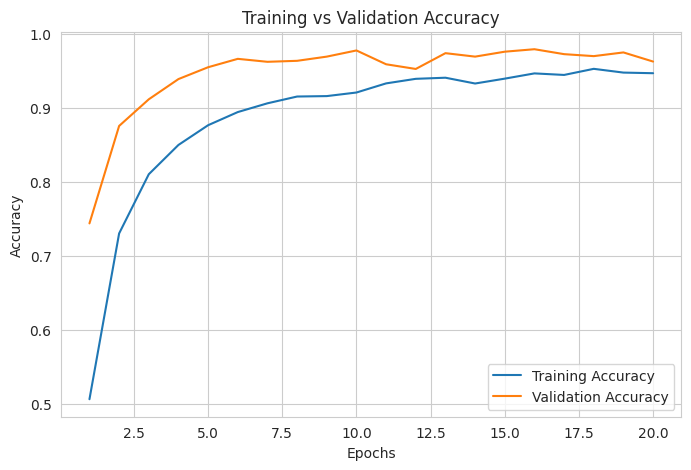

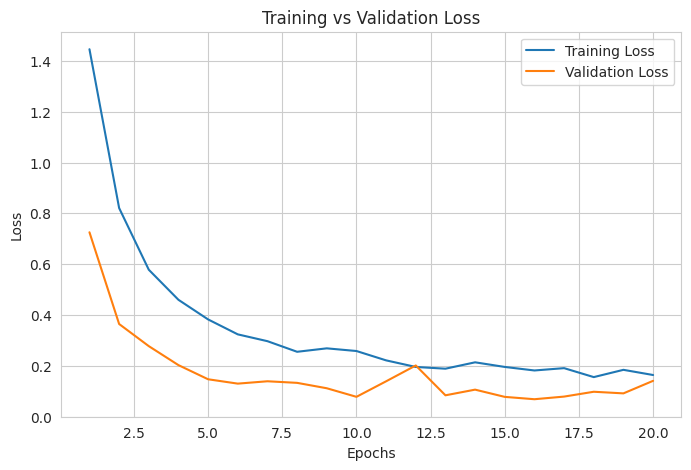

In [20]:
# Part 12: Plot Accuracy and Loss Curves
epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history['loss'], label='Training Loss')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()